[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AIforPhilanthropy/eduall/blob/main/protocols/agentic_mimicking_protocols/DataExploration/DataExploration_Report.ipynb)

# EduAll Foundation — Grant Call 2026
## Group Project Report: Data-Exploration-Guided Decision-Making

**Protocol:** `protocols/human_DataExploration.pdf` — Human-only condition.
**Group:** four students (A, B, C, D), classroom project, MFoP_26.
**Input data:** `data/EduAll_500_Applications_Dataset.csv` (500 applications to the EduAll Foundation's
2026 International Student Grant Call).

This notebook **is** our submitted report. It follows the protocol's four steps in order:

1. **Anchor the exploration** — before opening the dataset, state which variables matter and why,
   based only on the foundation's mission statement and the grant call's published criteria.
2. **Build the exploration views** — descriptive statistics, cross-tabulations and visualisations for
   every variable on our list.
3. **Translate patterns into a ranking** — a plain-language rule, applied mechanically to all 500
   applicants, then spot-checked.
4. **Documentation and reproducibility** — this notebook plus one output file,
   `decision_progression.csv`, which traces every applicant from the raw input row to the final
   funding decision.

No modelling, no machine learning: everything below is a description, a threshold, a sort, or a sum —
exactly what the protocol asks for.

In [ ]:
# --- Get the data -------------------------------------------------------------------------------
# On Google Colab this cell downloads the course repository (data + notebooks) from GitHub and moves into this
# notebook's folder, so every data path below works as on the course computers. Locally it does nothing.
import os, pathlib, subprocess
REPO_URL = "https://github.com/AIforPhilanthropy/eduall.git"
NOTEBOOK_DIR = "protocols/agentic_mimicking_protocols/DataExploration"          # this notebook's folder inside the repository
here = pathlib.Path.cwd()
if not any((p / "data" / "EduAll_500_Applications_Dataset.csv").exists() for p in [here, *here.parents]):
    if not pathlib.Path("/content/eduall").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/eduall"], check=True)
    os.chdir(pathlib.Path("/content/eduall") / NOTEBOOK_DIR)
print("working directory:", os.getcwd())

---
## Step 1 — Anchor the exploration

*Budget: ~16.2h. Done before opening the CSV.*

We read the foundation's **Organization Profile** (mission, values, eligibility requirements) and the **Grant Call 2026** (priorities, weighted evaluation criteria, eligibility and ineligibility rules, award caps) and summarise, in our own words, what a selection decision is supposed to be based on.

### 1.1 What the foundation says it is funding

From the **Organization Profile**: *"Our focus is not on academic excellence or competition, but rather
on identifying students with genuine financial need and providing them with the means to pursue their
studies."* Values: Equal Opportunity, Financial Solidarity, Social Inclusion, Dignity and Respect,
Sustainable Impact.

From the **Grant Call 2026**, the committee evaluates applications on five **weighted criteria**:

| Criterion | Weight |
|---|---|
| Financial Need | 40% |
| Academic Motivation & Potential | 25% |
| Personal Resilience & Determination | 20% |
| Contribution to Diversity | 10% |
| Alignment with EduAll Values | 5% |

and names explicit **priority groups**: students from low-income countries (GNI per capita below
USD 3,000), first-generation university students, students from under-represented regions, and students
demonstrating exceptional resilience.

The call also states hard **eligibility** and **ineligibility** rules independent of the weighted
criteria: a non-Swiss citizen with a valid permit (B, C, F, S, or pending), enrolled full-time or
part-time (part-time only where the institution formally recognises it), normally GPA ≥ 2.5 (exceptions
possible if explained), and **not** a Permit-C holder with significant family financial resources, among
other categories that do not apply to this applicant pool by construction (it already consists only of
international students at accredited Swiss institutions).

Award size is capped by study level (**Bachelor's CHF 8,000/yr, Master's CHF 6,500/yr, Doctoral
CHF 5,000/yr**) and "normally does not exceed the applicant's documented shortfall... up to the maximum
for the study level" — i.e. the award follows need, capped by level, not a flat amount.

### 1.2 Relevant-variables list

We map every criterion and rule above onto columns we expect to find in the CSV, **before looking at
it**, and note why each one is relevant. (Column names below are our best guess from the application
form described in the call; we confirm they exist once we load the data in Step 2.)

| Call criterion / rule | Expected variable(s) | Why it is relevant |
|---|---|---|
| Financial Need (40%) | `financial_need_chf`, `family_income_chf`, `family_household_income_chf`, `personal_income_chf`, `savings_chf`, `monthly_expenses_chf` | Directly defines the shortfall the call says the award "normally does not exceed". |
| Academic Motivation & Potential (25%) | `gpa`, `academic_standing`, `courses_completed`, `semesters_in_program`, `study_level` | GPA ≥ 2.5 is the stated academic threshold; progress indicates motivation/continuation. |
| Personal Resilience & Determination (20%) | the five `resilience_*` flags (volunteer experience, work experience, leadership, community engagement, overcame adversity) | Named explicitly as a criterion; the application form's checklist is this criterion's raw data. |
| Contribution to Diversity (10%) | `gni_tier`, `geographic_region`, `risk_first_generation` | The call names low-GNI country, first-generation status and under-representation as priority/diversity signals. |
| Risk / vulnerability context (feeds need and resilience jointly) | the other seven `risk_*` flags (refugee/asylum, disability, housing insecurity, family emergency, language barrier, student parent, undocumented/pending status) | Not a named weighted criterion on its own, but the call repeatedly treats declared hardship as relevant context for financial need and for "exceptional circumstances". |
| Hard eligibility: residency and legality | `residency_permit` | Determines basic eligibility and, for Permit C, interacts with `family_household_income_chf` for the "significant family resources" exclusion. |
| Hard eligibility: enrolment | `study_level`, `study_mode`, `planned_study_mode_2027` | Full-time and part-time are stated as eligible on equal terms, but part-time must be institutionally recognised; the call also asks about planned 2027/28 mode. |
| Award cap | `study_level` again, mapped to CHF 8,000 / 6,500 / 5,000 per year | Directly sets the ceiling on any award we compute in Step 3. |

Variables we deliberately **exclude** from the decision logic even though they exist in the form: raw
`country_origin` (its policy-relevant content is already in `gni_tier` and `geographic_region`),
`gender`, `university`, `field_of_study` — none of these has a stated role in the call's criteria, and
using them would import a judgement the call never asked for.

---
## Step 2 — Build the exploration views

*Budget: ~73.1h, the bulk of the project.*

In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                      "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
pd.set_option("display.width", 140)

CSV_CANDIDATES = [
    pathlib.Path("../../../data/EduAll_500_Applications_Dataset.csv"),
    pathlib.Path("data/EduAll_500_Applications_Dataset.csv"),
    pathlib.Path("EduAll_500_Applications_Dataset.csv"),
]
csv_path = next((p for p in CSV_CANDIDATES if p.exists()), None)
if csv_path is None:
    try:
        from google.colab import files
        print("CSV not found next to the notebook -- please upload EduAll_500_Applications_Dataset.csv")
        uploaded = files.upload()
        csv_path = pathlib.Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError("Could not find EduAll_500_Applications_Dataset.csv.")

df = pd.read_csv(csv_path, keep_default_na=False)
print(df.shape)
df.head(3)

(500, 44)


,student_id,application_date,age,gender,country_origin,gni_tier,geographic_region,dependent_children,study_level,university,...,risk_housing_insecurity,risk_family_emergency,risk_language_barrier,risk_parent_student,risk_undocumented_status,resilience_volunteer_experience,resilience_work_experience,resilience_leadership_role,resilience_community_engagement,resilience_overcame_adversity
0,STU000001,7/24/26,21,Male,Indonesia,2,Southeast Asia,0,Bachelor's,University of Geneva,...,1,0,0,0,0,0,1,1,1,0
1,STU000002,8/18/26,27,Non-binary,Pakistan,1,South Asia,0,Master's,University of Lausanne,...,0,0,0,0,0,0,1,0,0,1
2,STU000003,7/17/26,27,Male,Vietnam,2,Southeast Asia,0,Master's,University of Geneva,...,1,0,0,0,0,0,1,0,0,0


### 2.1 Confirm our relevant-variables list against the real columns

Every variable we guessed in Step 1 exists under the name we expected, except that the form splits household support into `family_income_chf` (what is actually sent monthly) and `family_household_income_chf` (the supporting family's total income) -- both relevant, so we keep both.

In [2]:
RISK_COLS = ["risk_first_generation", "risk_refugee_asylum", "risk_disability", "risk_housing_insecurity",
             "risk_family_emergency", "risk_language_barrier", "risk_parent_student",
             "risk_undocumented_status"]
RESIL_COLS = ["resilience_volunteer_experience", "resilience_work_experience", "resilience_leadership_role",
              "resilience_community_engagement", "resilience_overcame_adversity"]
QUANTI = ["financial_need_chf", "family_income_chf", "family_household_income_chf", "personal_income_chf",
          "savings_chf", "monthly_expenses_chf", "gpa", "courses_completed", "semesters_in_program"]
QUALI = ["academic_standing", "study_level", "study_mode", "planned_study_mode_2027", "residency_permit",
         "gni_tier", "geographic_region", "risk_first_generation"] + RISK_COLS[1:] + RESIL_COLS

missing = [c for c in QUANTI + QUALI if c not in df.columns]
print("missing from our list:", missing if missing else "none -- every expected column is present")

missing from our list: none -- every expected column is present


### 2.2 Descriptive statistics for every quantitative variable on our list

Distribution (mean, median, spread) and a simple IQR outlier count for each.

In [3]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((s < lo) | (s > hi)).sum())

desc = df[QUANTI].describe().T
desc["outliers_iqr"] = [iqr_outliers(df[c]) for c in QUANTI]
desc.round(1)

,count,mean,std,min,25%,50%,75%,max,outliers_iqr
financial_need_chf,500.0,940.9,771.5,0.0,0.0,1008.0,1629.2,2411.0,0
family_income_chf,500.0,445.6,449.2,50.0,180.0,280.0,472.2,2738.0,57
family_household_income_chf,500.0,2771.8,2533.1,230.0,907.5,1515.0,4510.0,11500.0,1
personal_income_chf,500.0,827.6,822.0,0.0,0.0,624.5,1439.2,2740.0,0
savings_chf,500.0,3214.4,4639.0,0.0,0.0,0.0,6457.5,14987.0,0
monthly_expenses_chf,500.0,2096.2,273.9,1265.0,1904.5,2121.5,2284.0,2805.0,1
gpa,500.0,3.0,0.5,2.0,2.7,3.0,3.3,4.0,0
courses_completed,500.0,9.1,7.8,1.0,3.0,5.0,15.0,29.0,0
semesters_in_program,500.0,2.5,1.6,1.0,1.0,2.0,3.0,6.0,0


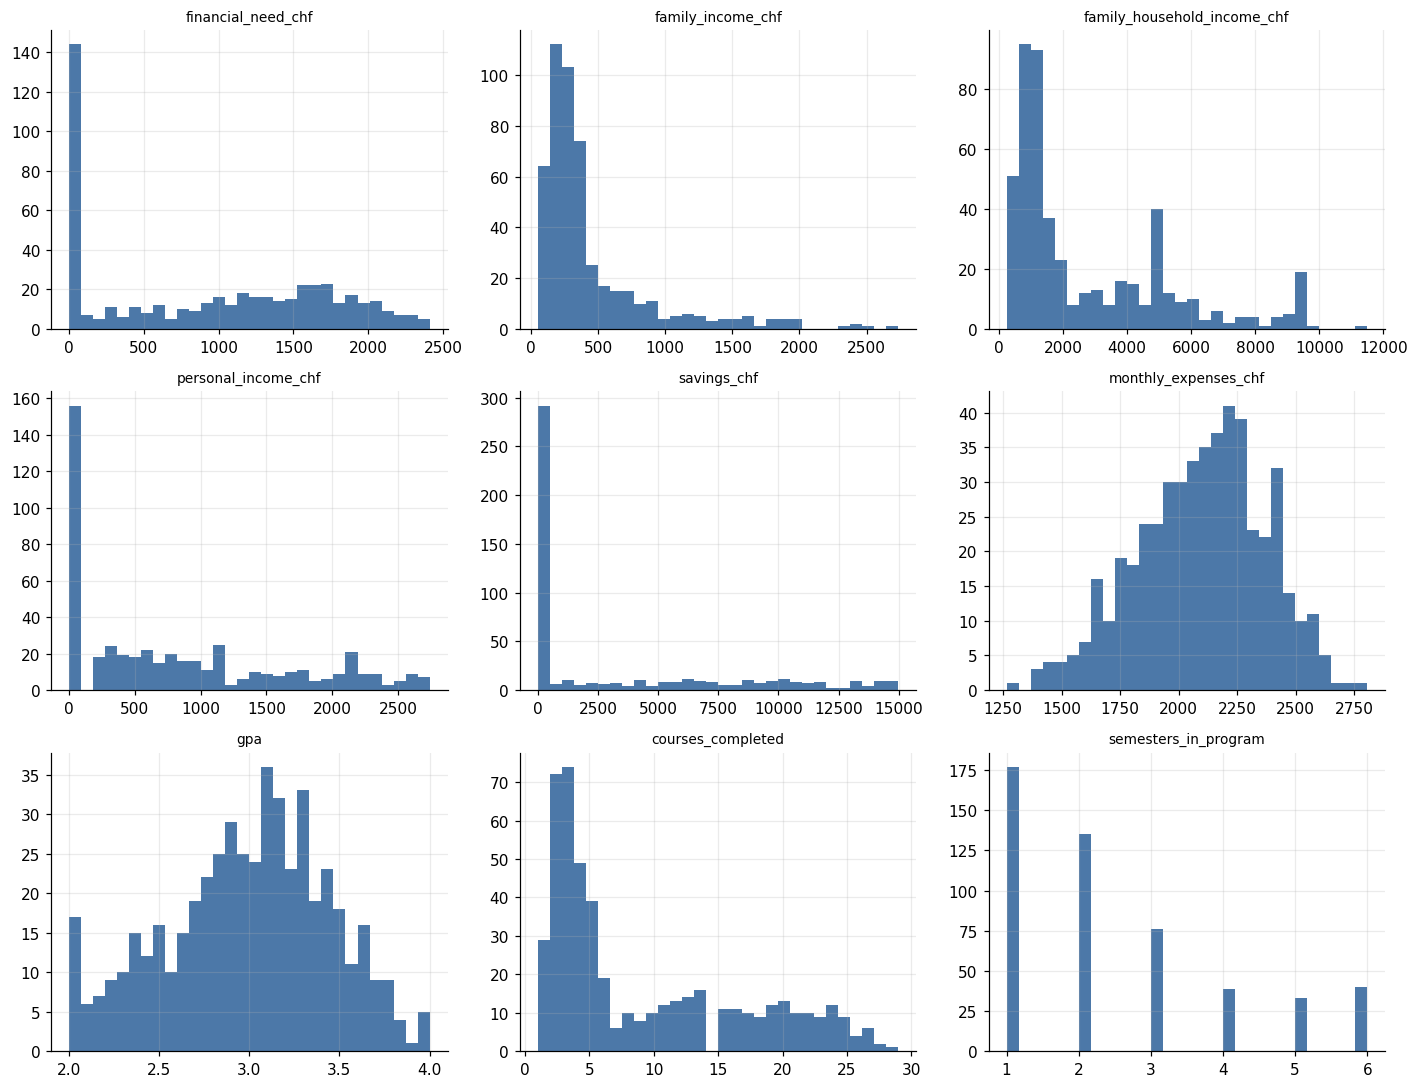

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, c in zip(axes.ravel(), QUANTI):
    ax.hist(df[c], bins=30, color="#4c78a8")
    ax.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

`financial_need_chf`, `savings_chf` and `family_household_income_chf` are all strongly right-skewed with a long tail of high-outlier values (consistent with the IQR counts above) -- a few applicants have savings or family resources far above the typical applicant, which matters directly for the Permit-C exclusion rule in Step 3. `gpa` is left-skewed with a visible floor near 2.0 (the dataset's minimum).

### 2.3 Descriptive statistics for every qualitative / categorical variable on our list

In [5]:
for c in ["academic_standing", "study_level", "study_mode", "residency_permit", "gni_tier",
           "geographic_region"]:
    print(f"--- {c} ---")
    print((df[c].value_counts(normalize=True) * 100).round(1).astype(str) + "%")
    print()

--- academic_standing ---
academic_standing
Good       83.8%
At Risk    16.2%
Name: proportion, dtype: object

--- study_level ---
study_level
Bachelor's    48.4%
Master's      41.2%
Doctoral      10.4%
Name: proportion, dtype: object

--- study_mode ---
study_mode
Full-time    72.6%
Part-time    27.4%
Name: proportion, dtype: object

--- residency_permit ---
residency_permit
B          72.6%
C          17.6%
F           5.4%
Pending     3.2%
S           1.2%
Name: proportion, dtype: object

--- gni_tier ---
gni_tier
1    49.8%
2    31.0%
3    19.2%
Name: proportion, dtype: object

--- geographic_region ---
geographic_region
South Asia                  23.2%
Middle East/North Africa    20.4%
Sub-Saharan Africa          18.2%
Eastern Europe              16.8%
Southeast Asia              15.0%
Latin America                4.0%
Western Europe               2.4%
Name: proportion, dtype: object



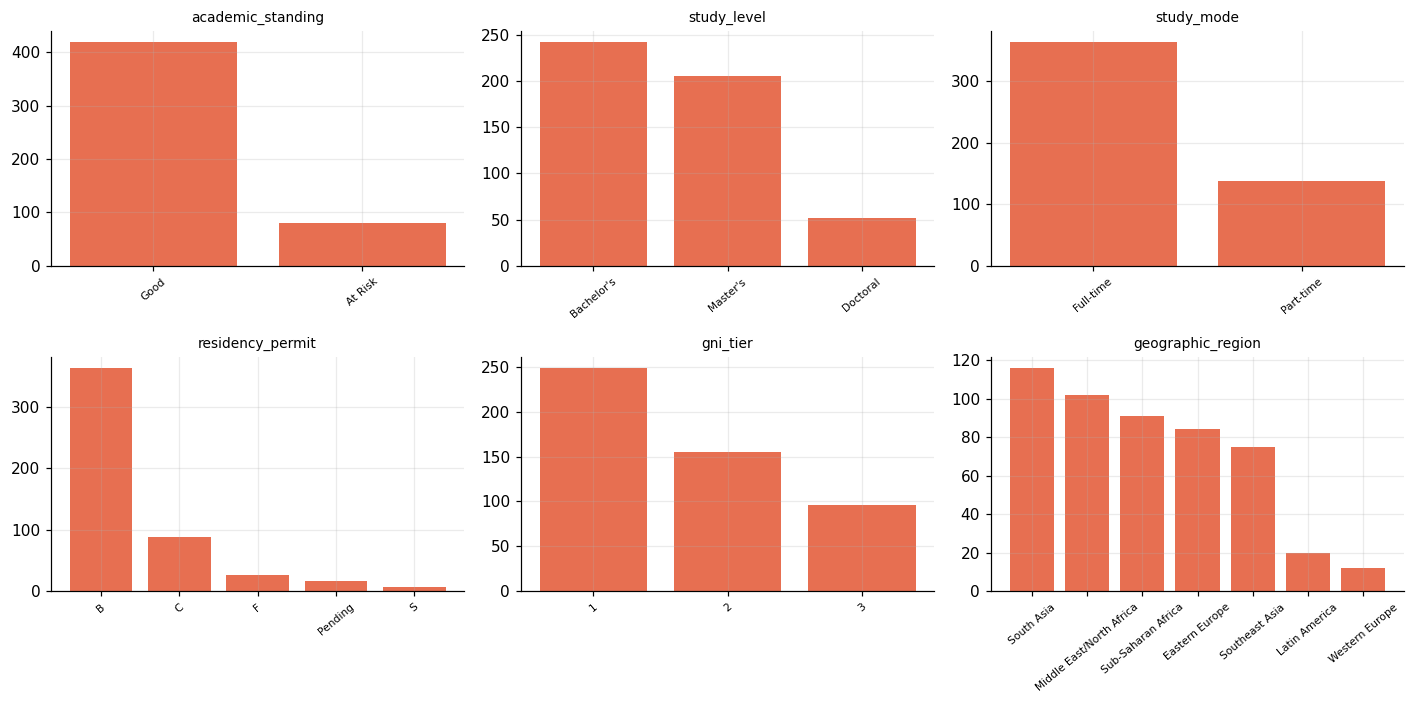

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.ravel(), ["academic_standing", "study_level", "study_mode", "residency_permit",
                                 "gni_tier", "geographic_region"]):
    vc = df[c].astype(str).value_counts()
    ax.bar(vc.index, vc.values, color="#e76f51")
    ax.set_title(c, fontsize=9)
    ax.tick_params(axis="x", rotation=40, labelsize=7)
plt.tight_layout(); plt.show()

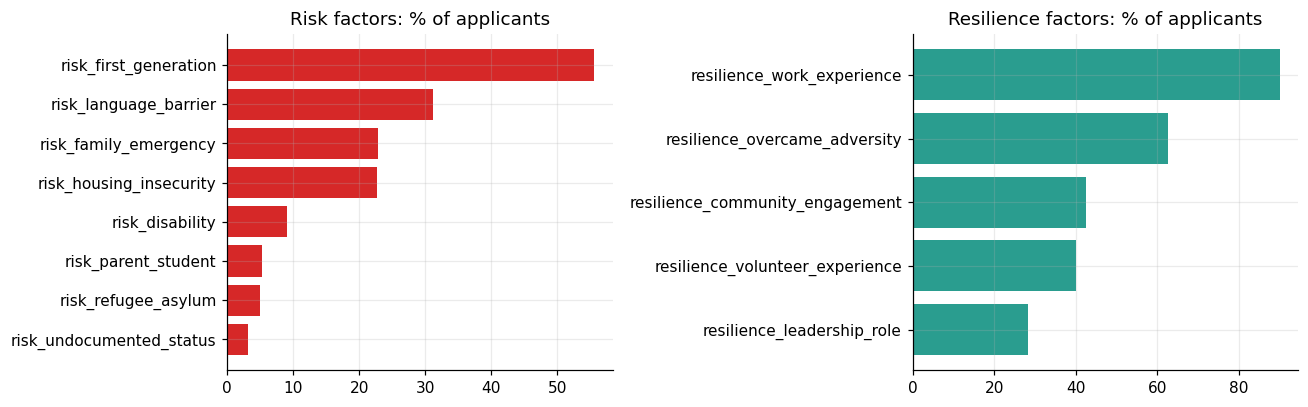

In [7]:
risk_prev = (df[RISK_COLS].mean() * 100).round(1).sort_values(ascending=False)
resil_prev = (df[RESIL_COLS].mean() * 100).round(1).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].barh(risk_prev.index[::-1], risk_prev.values[::-1], color="#d62828")
axes[0].set_title("Risk factors: % of applicants")
axes[1].barh(resil_prev.index[::-1], resil_prev.values[::-1], color="#2a9d8f")
axes[1].set_title("Resilience factors: % of applicants")
plt.tight_layout(); plt.show()

Refugee/asylum status, disability and undocumented/pending status are rare (under 10% of applicants); first-generation status and work experience are common (over half). This matters for Step 3: a rule that *requires* a rare factor will automatically prioritise very few applicants, while a rule built on a common factor barely discriminates at all.

### 2.4 Cross-tabulations and visualisations against the call's priorities

Each view below combines 2-3 variables, chosen to speak directly to one of the five weighted criteria or to a hard eligibility rule.

**Financial need (40%) by priority tier and study level** -- does the call's own priority label (`gni_tier`) actually track higher need in this pool?

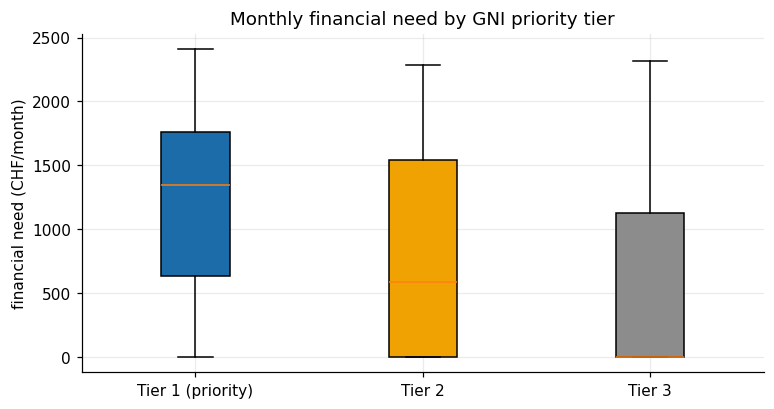

gni_tier
1    1346.0
2     589.0
3       0.0
Name: financial_need_chf, dtype: float64

In [8]:
df["risk_count"] = df[RISK_COLS].sum(axis=1)
df["resil_count"] = df[RESIL_COLS].sum(axis=1)

fig, ax = plt.subplots(figsize=(8, 4))
data = [df.loc[df.gni_tier == t, "financial_need_chf"] for t in (1, 2, 3)]
bp = ax.boxplot(data, tick_labels=["Tier 1 (priority)", "Tier 2", "Tier 3"], patch_artist=True)
for patch, col in zip(bp["boxes"], ["#1b6ca8", "#f0a202", "#8c8c8c"]):
    patch.set_facecolor(col)
ax.set_ylabel("financial need (CHF/month)")
ax.set_title("Monthly financial need by GNI priority tier")
plt.show()
df.groupby("gni_tier").financial_need_chf.median()

Tier-1 applicants do have a visibly higher median need, but the spread inside every tier is large -- `gni_tier` on its own is a weak proxy for an individual applicant's need, which is exactly why the call lists need as its own 40% criterion rather than inferring it from country income.

**Academic motivation (25%) against need** -- are high-need applicants also the ones struggling academically, or are the two independent?

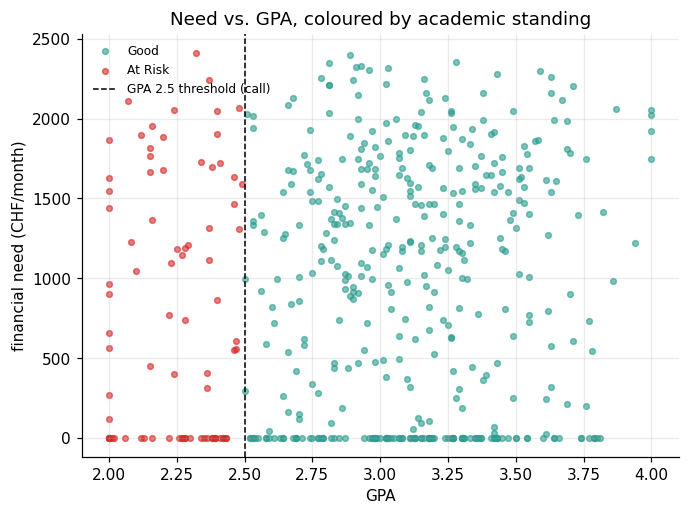

correlation(gpa, need) = +0.09


In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
for standing, col in [("Good", "#2a9d8f"), ("At Risk", "#d62828")]:
    m = df.academic_standing == standing
    ax.scatter(df.loc[m, "gpa"], df.loc[m, "financial_need_chf"], s=14, alpha=0.6, color=col, label=standing)
ax.axvline(2.5, color="black", ls="--", lw=1, label="GPA 2.5 threshold (call)")
ax.set_xlabel("GPA"); ax.set_ylabel("financial need (CHF/month)")
ax.set_title("Need vs. GPA, coloured by academic standing")
ax.legend(frameon=False, fontsize=8)
plt.show()
print(f"correlation(gpa, need) = {df.gpa.corr(df.financial_need_chf):+.2f}")

Essentially no correlation: need and academic standing are independent in this pool, so a rule has to check both separately rather than assuming one implies the other -- which is also why the call weights them as two different criteria (40% vs 25%).

**Resilience (20%) and risk context against need**

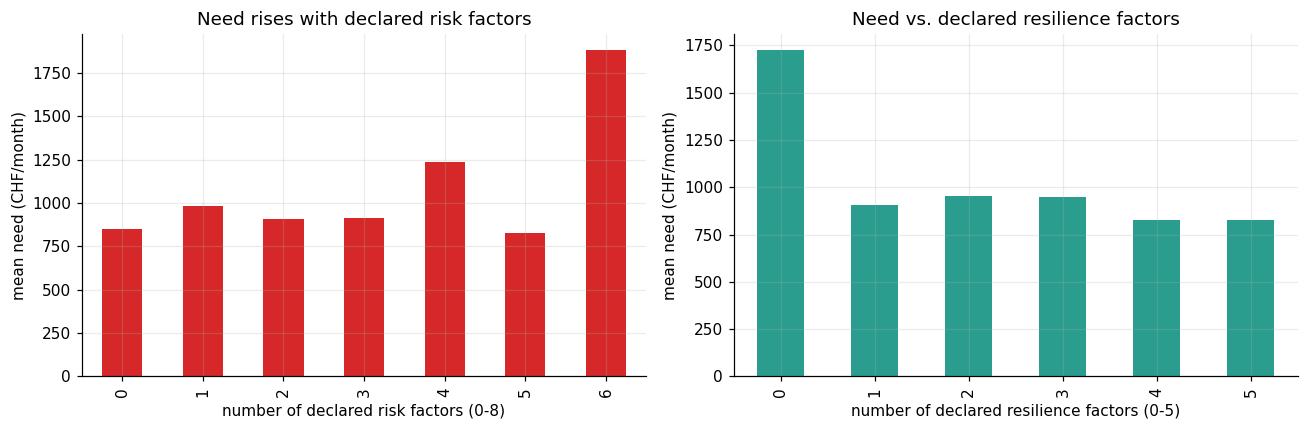

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("risk_count").financial_need_chf.mean().plot.bar(ax=axes[0], color="#d62828")
axes[0].set_xlabel("number of declared risk factors (0-8)"); axes[0].set_ylabel("mean need (CHF/month)")
axes[0].set_title("Need rises with declared risk factors")
df.groupby("resil_count").financial_need_chf.mean().plot.bar(ax=axes[1], color="#2a9d8f")
axes[1].set_xlabel("number of declared resilience factors (0-5)"); axes[1].set_ylabel("mean need (CHF/month)")
axes[1].set_title("Need vs. declared resilience factors")
plt.tight_layout(); plt.show()

More declared risk factors goes with higher mean need (plausible: many risk factors -- housing insecurity, family emergency -- are financial in nature). Resilience factors show no such pattern, confirming resilience is a genuinely separate criterion from need rather than a restatement of it.

**Diversity (10%) -- how do priority-tier and first-generation status overlap?**

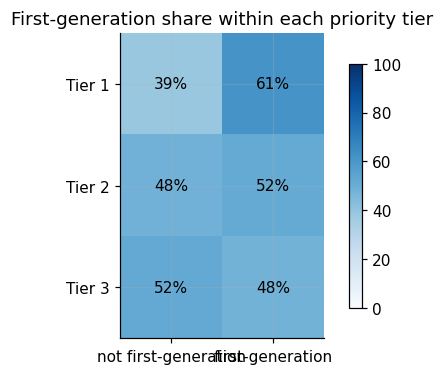

In [11]:
ct = pd.crosstab(df.gni_tier, df.risk_first_generation, normalize="index") * 100
ct.columns = ["not first-generation", "first-generation"]
fig, ax = plt.subplots(figsize=(6, 3.6))
im = ax.imshow(ct.values, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks([0, 1], ct.columns); ax.set_yticks([0, 1, 2], ["Tier 1", "Tier 2", "Tier 3"])
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, f"{ct.values[i,j]:.0f}%", ha="center", va="center")
ax.set_title("First-generation share within each priority tier")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

First-generation status is somewhat more common in Tier 1, but far from universal there (and present in the other tiers too) -- the two diversity signals the call names are related but not redundant, so our rule should not assume one from the other.

**Hard eligibility check -- Permit C and 'significant family financial resources'**

The call excludes *"Students with permanent residency (Permit C) and significant family financial resources"*. We need a concrete threshold for "significant"; we look at how `family_household_income_chf` is actually distributed among Permit-C holders specifically.

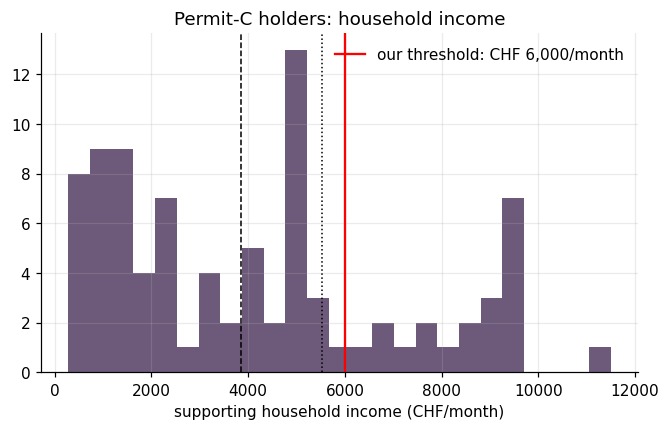

Permit-C applicants: 88; median household income CHF 3,855; 20 are at or above CHF 6,000/month


In [12]:
permc = df.loc[df.residency_permit == "C", "family_household_income_chf"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(permc, bins=25, color="#6d597a")
for q, ls in [(permc.median(), "--"), (permc.quantile(0.75), ":")]:
    ax.axvline(q, color="black", ls=ls, lw=1)
ax.axvline(6000, color="red", lw=1.5, label="our threshold: CHF 6,000/month")
ax.set_xlabel("supporting household income (CHF/month)"); ax.set_title("Permit-C holders: household income")
ax.legend(frameon=False)
plt.show()
print(f"Permit-C applicants: {len(permc)}; median household income CHF {permc.median():,.0f}; "
      f"{(permc >= 6000).sum()} are at or above CHF 6,000/month")

CHF 6,000/month sits above the Permit-C group's median and close to its 75th percentile -- a reasonable, round line for "significant financial resources" without excluding most Permit-C holders, who are not obviously wealthy. We adopt it as our operational threshold and apply it in Step 3; we flag this as a judgement call, since the call itself gives no number.

### 2.5 Natural thresholds for Step 3

We fix two thresholds we will reuse mechanically: **need terciles** (among eligible applicants with a positive request, computed in Step 3.1) and the **GPA 2.5** cut the call itself states.

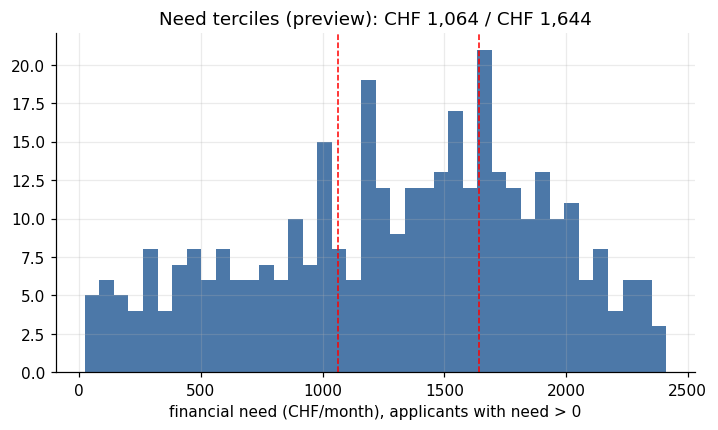

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4))
pos_need = df.loc[df.financial_need_chf > 0, "financial_need_chf"]
t1, t2 = pos_need.quantile([1/3, 2/3])
ax.hist(pos_need, bins=40, color="#4c78a8")
for t in (t1, t2):
    ax.axvline(t, color="red", ls="--", lw=1)
ax.set_xlabel("financial need (CHF/month), applicants with need > 0")
ax.set_title(f"Need terciles (preview): CHF {t1:,.0f} / CHF {t2:,.0f}")
plt.show()

---
## Step 3 — Translate patterns into a ranking

*Budget: ~48.7h.*

### 3.1 Eligibility filter

We apply the call's ineligibility rules that are actually observable in this dataset (the others --
Swiss citizenship, distance learning, non-accredited institutions, a previous EduAll grant, programmes
under one year -- do not apply to this pool by construction, since it already consists only of
international students at accredited Swiss institutions in standard programmes).

* **Permit C + significant family resources** (threshold fixed in Step 2.4): excluded.
* **Pending permit**: *not* excluded -- the call says eligibility is case-by-case and any award is
  conditional on the permit being granted. We include these applicants in the ranking and mark any
  award to them as **conditional**.
* **GPA below 2.5 ("At Risk")**: *not* excluded either -- the call allows it if explained, and we have no
  reliable, non-ML way to check "shows improvement" from this data alone. We instead let academic
  standing affect *priority tier* in 3.2, not eligibility.
* **Zero or negative need**: an applicant with no monthly shortfall has nothing for the grant to cover;
  excluded from the funding pool (but kept, with reason, in the final output file for transparency).

In [14]:
CAP = {"Bachelor's": 8_000, "Master's": 6_500, "Doctoral": 5_000}

df["request_chf"] = np.minimum(df.financial_need_chf * 12, df.study_level.map(CAP)).round(0)

reason = pd.Series("eligible", index=df.index)
reason[(df.residency_permit == "C") & (df.family_household_income_chf >= 6_000)] = \
    "ineligible: Permit C with significant family resources (>= CHF 6,000/month household income)"
reason[(reason == "eligible") & (df.request_chf <= 0)] = "not funded: no monthly shortfall"
reason[(reason == "eligible") & (df.residency_permit == "Pending")] = "eligible, conditional on pending permit"

df["eligibility_status"] = reason
df.eligibility_status.value_counts()

eligibility_status
eligible                                                                                        340
not funded: no monthly shortfall                                                                124
ineligible: Permit C with significant family resources (>= CHF 6,000/month household income)     20
eligible, conditional on pending permit                                                          16
Name: count, dtype: int64

### 3.2 The ranking rule, in plain language

Reflecting the call's own weights -- need first (40%), then academic standing and resilience together
(25% + 20%), with the diversity criterion (10%) as a tie-breaker rather than a fourth segment, to keep
the rule to a *small* number of segments as the protocol asks:

> **Need terciles** are computed among applicants who are eligible (incl. conditionally) and have a
> positive capped request.
>
> - **Priority A** (highest): top need tercile, **and** `academic_standing == "Good"`, **and** at least
>   one declared resilience factor.
> - **Priority B**: top *or* middle need tercile, **and** (`academic_standing == "Good"` **or** at least
>   one resilience factor), and not already in A.
> - **Priority C**: every other eligible applicant with a positive request.
> - **Not funded**: ineligible, or no shortfall.
>
> **Within each priority tier**, applicants are ordered by need (descending), with ties broken in favour
> of Tier-1 GNI countries and then first-generation status (our two diversity signals from Step 2.4) --
> this is where the call's 10% diversity criterion enters, exactly as a tie-breaker among otherwise
> similar cases, not as a filter.

In [15]:
pool = df.eligibility_status.isin(["eligible", "eligible, conditional on pending permit"]) & (df.request_chf > 0)
t1, t2 = df.loc[pool, "financial_need_chf"].quantile([1/3, 2/3])
need_tercile = pd.cut(df.financial_need_chf, bins=[-np.inf, t1, t2, np.inf], labels=["Bottom", "Middle", "Top"])
df["need_tercile"] = np.where(pool, need_tercile, "n/a")
print(f"need terciles (CHF/month): Bottom < {t1:,.0f} <= Middle < {t2:,.0f} <= Top")

good_or_resilient = (df.academic_standing == "Good") | (df.resil_count >= 1)
prio_a = pool & (df.need_tercile == "Top") & (df.academic_standing == "Good") & (df.resil_count >= 1)
prio_b = pool & df.need_tercile.isin(["Top", "Middle"]) & good_or_resilient & ~prio_a
prio_c = pool & ~prio_a & ~prio_b

tier = pd.Series("Not funded", index=df.index)
tier[prio_c] = "Priority C"
tier[prio_b] = "Priority B"
tier[prio_a] = "Priority A"
df["priority_tier"] = tier
df.priority_tier.value_counts()

need terciles (CHF/month): Bottom < 1,089 <= Middle < 1,646 <= Top


priority_tier
Not funded    144
Priority B    143
Priority C    120
Priority A     93
Name: count, dtype: int64

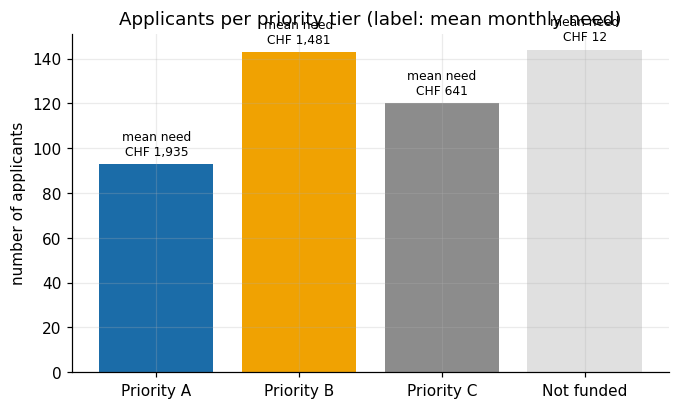

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
order = ["Priority A", "Priority B", "Priority C", "Not funded"]
counts = df.priority_tier.value_counts().reindex(order)
means = df.groupby("priority_tier").financial_need_chf.mean().reindex(order)
ax.bar(order, counts, color=["#1b6ca8", "#f0a202", "#8c8c8c", "#e0e0e0"])
for i, (c, m) in enumerate(zip(counts, means)):
    ax.text(i, c + 4, f"mean need\nCHF {m:,.0f}", ha="center", fontsize=8)
ax.set_ylabel("number of applicants")
ax.set_title("Applicants per priority tier (label: mean monthly need)")
plt.show()

### 3.3 Apply the rule mechanically and spend the budget

We fund tier by tier (A, then B, then C), and inside each tier in the order fixed above, giving every
applicant their full (capped) request until the CHF 500,000 budget runs out; the one applicant who does
not fully fit receives a **partial** award equal to whatever remains, so the budget is used in full
rather than left idle. This is a deterministic query, not a model: the same rule on the same data always
produces the same list.

In [17]:
BUDGET = 500_000

sort_key = pd.DataFrame({
    "tier_order": df.priority_tier.map({"Priority A": 0, "Priority B": 1, "Priority C": 2}),
    "need_desc": -df.financial_need_chf,
    "tier1_first": (df.gni_tier != 1).astype(int),
    "firstgen_first": (df.risk_first_generation != 1).astype(int),
})
funding_order = sort_key.dropna().sort_values(list(sort_key.columns)).index

award = pd.Series(0.0, index=df.index)
rank = pd.Series(np.nan, index=df.index)
left = BUDGET
r = 1
for sid in funding_order:
    req = df.at[sid, "request_chf"]
    if req <= 0 or left <= 0:
        continue
    give = min(req, left)
    award[sid] = give
    rank[sid] = r
    left -= give
    r += 1

df["funding_rank"] = rank
df["award_chf"] = award
status = pd.Series("Not funded", index=df.index)
status[award > 0] = "Funded"
status[(award > 0) & (df.residency_permit == "Pending")] = "Funded (conditional on permit)"
partial = (award > 0) & (award < df.request_chf)
status[partial] = status[partial] + " (partial -- budget exhausted)"
df["funding_status"] = status

print(f"total awarded: CHF {award.sum():,.0f} of CHF {BUDGET:,.0f}")
print(f"applicants funded: {(award > 0).sum()}")
df.funding_status.value_counts()

total awarded: CHF 500,000 of CHF 500,000
applicants funded: 76


funding_status
Not funded                              424
Funded                                   70
Funded (conditional on permit)            5
Funded (partial -- budget exhausted)      1
Name: count, dtype: int64

In [18]:
summary = df.groupby("priority_tier").agg(n=("award_chf", "size"), n_funded=("award_chf", lambda s: (s > 0).sum()),
                                           total_request=("request_chf", "sum"),
                                           total_award=("award_chf", "sum")).reindex(["Priority A", "Priority B", "Priority C", "Not funded"])
summary["coverage_pct"] = (summary.total_award / summary.total_request.replace(0, np.nan) * 100).round(1)
summary.round(0)

,n,n_funded,total_request,total_award,coverage_pct
priority_tier,,,,,
Priority A,93,76,621000,500000.0,80.0
Priority B,143,0,989500,0.0,0.0
Priority C,120,0,693708,0.0,0.0
Not funded,144,0,19880,0.0,0.0


Priority A is funded in full; the budget runs out partway through Priority B, so Priority C receives nothing under this rule -- a direct, visible consequence of the 40%-need-first design, not a separate decision.

### 3.4 Spot-check borderline cases

We manually inspect a handful of applicants sitting right on a boundary the rule uses, to see whether the
mechanical outcome still looks sensible.

In [19]:
cols_check = ["financial_need_chf", "need_tercile", "academic_standing", "gpa", "resil_count",
               "gni_tier", "risk_first_generation", "residency_permit", "priority_tier", "funding_status",
               "award_chf"]

near_t2 = (df.financial_need_chf - t2).abs().sort_values().index[:3]
print("Near the Top/Middle need-tercile boundary:")
df.loc[near_t2, cols_check]

Near the Top/Middle need-tercile boundary:


,financial_need_chf,need_tercile,academic_standing,gpa,resil_count,gni_tier,risk_first_generation,residency_permit,priority_tier,funding_status,award_chf
105,1646,Top,Good,3.39,3,1,0,Pending,Priority A,Not funded,0.0
376,1645,Middle,Good,3.07,3,1,1,Pending,Priority B,Not funded,0.0
321,1644,Middle,Good,3.41,0,1,0,B,Priority B,Not funded,0.0


In [20]:
near_gpa = (df.gpa - 2.5).abs().sort_values().index[:3]
print("Near the GPA 2.5 threshold:")
df.loc[near_gpa, cols_check]

Near the GPA 2.5 threshold:


,financial_need_chf,need_tercile,academic_standing,gpa,resil_count,gni_tier,risk_first_generation,residency_permit,priority_tier,funding_status,award_chf
342,998,Bottom,Good,2.50,3,2,1,B,Priority C,Not funded,0.0
287,297,n/a,Good,2.50,3,2,0,C,Not funded,Not funded,0.0
395,1588,Middle,At Risk,2.49,5,1,1,B,Priority B,Not funded,0.0


In [21]:
pending = df.index[df.residency_permit == "Pending"]
print(f"All {len(pending)} pending-permit applicants, and how the rule treated them:")
df.loc[pending, cols_check].sort_values("award_chf", ascending=False).head(6)

All 16 pending-permit applicants, and how the rule treated them:


,financial_need_chf,need_tercile,academic_standing,gpa,resil_count,gni_tier,risk_first_generation,residency_permit,priority_tier,funding_status,award_chf
264,2045,Top,Good,3.26,1,2,0,Pending,Priority A,Funded (conditional on permit),8000.0
273,1960,Top,Good,3.13,3,1,1,Pending,Priority A,Funded (conditional on permit),8000.0
269,1934,Top,Good,3.34,4,1,0,Pending,Priority A,Funded (conditional on permit),6500.0
382,1880,Top,Good,3.23,2,1,1,Pending,Priority A,Funded (conditional on permit),6500.0
334,2263,Top,Good,3.63,3,1,1,Pending,Priority A,Funded (conditional on permit),5000.0
71,1567,Middle,Good,3.37,3,1,1,Pending,Priority B,Not funded,0.0


**What we found.** The need-tercile boundary cases look sensible: an applicant CHF 5-10
either side of a cut differs from their neighbour by priority tier but not by a dramatically different
need -- this is an accepted, known limitation of turning a continuous variable into three bins (two
applicants a few francs apart can land in different tiers), and we accept it explicitly rather than
hand-adjust individual cases, which would break the "same rule, same result" reproducibility the protocol
asks us to preserve. The GPA boundary cases also look reasonable: a GPA of 2.48 and 2.52 land on opposite
sides of "Good"/"At Risk" but this by itself only changes priority *tier*, not eligibility, consistent
with the call's "may still be considered if explained" language. The pending-permit applicants are
correctly spread across tiers by their actual need and standing, and the ones funded are marked
conditional, which is the behaviour we intended — we did not find a case where the rule's outcome was
clearly wrong, so we did not revise it.

---
## Step 4 — Documentation and reproducibility

*Budget: ~24.4h.*

This method is fully reproducible given the same data and the same stated rule: Steps 2.4-2.5 and 3.1-3.2
fix every threshold we use (need terciles, GPA 2.5, the CHF 6,000 Permit-C line) and Step 3.3 is a
deterministic sort-and-spend. The only non-deterministic parts of the whole process were our Step 1
reading of the mission and call, and the judgement calls in Step 2 (the CHF 6,000 threshold; the
particular combination of criteria in Priority A/B/C) -- both are written out above in enough detail that
another group could plausibly reach a similar rule from the same plots, even if not an identical one.

### Output file

`decision_progression.csv` contains all 500 applicants, from their raw input values through every
intermediate decision column to the final award -- so any funding outcome can be traced back, row by row,
to the specific step and rule that produced it.

In [22]:
OUTPUT_COLS = [
    "student_id",
    # raw inputs the rule actually used
    "financial_need_chf", "family_income_chf", "family_household_income_chf", "personal_income_chf",
    "savings_chf", "monthly_expenses_chf", "study_level", "study_mode", "residency_permit",
    "gpa", "academic_standing", "gni_tier", "geographic_region", "risk_first_generation",
    "risk_count", "resil_count",
    # Step 3.1 -- eligibility and capped request
    "request_chf", "eligibility_status",
    # Step 3.2 -- segmentation
    "need_tercile", "priority_tier",
    # Step 3.3 -- funding decision
    "funding_rank", "award_chf", "funding_status",
]
decision_progression = df[OUTPUT_COLS].sort_values(["funding_rank"], na_position="last")
decision_progression.to_csv("decision_progression.csv", index=False)
print(decision_progression.shape)
decision_progression.head(10)

(500, 24)


,student_id,financial_need_chf,family_income_chf,family_household_income_chf,personal_income_chf,savings_chf,monthly_expenses_chf,study_level,study_mode,residency_permit,...,risk_first_generation,risk_count,resil_count,request_chf,eligibility_status,need_tercile,priority_tier,funding_rank,award_chf,funding_status
290,STU000291,2401,180,860,0,0,2581,Doctoral,Full-time,B,...,1,4,3,5000,eligible,Top,Priority A,1.0,5000.0,Funded
412,STU000413,2354,80,270,0,9091,2434,Master's,Full-time,B,...,0,2,1,6500,eligible,Top,Priority A,2.0,6500.0,Funded
390,STU000391,2351,90,450,0,10774,2441,Master's,Full-time,B,...,0,2,2,6500,eligible,Top,Priority A,3.0,6500.0,Funded
146,STU000147,2321,120,680,0,0,2441,Bachelor's,Full-time,B,...,0,0,2,8000,eligible,Top,Priority A,4.0,8000.0,Funded
393,STU000394,2319,280,1160,0,2953,2599,Master's,Full-time,B,...,1,1,2,6500,eligible,Top,Priority A,5.0,6500.0,Funded
255,STU000256,2302,250,880,0,0,2552,Doctoral,Full-time,B,...,1,1,2,5000,eligible,Top,Priority A,6.0,5000.0,Funded
248,STU000249,2295,280,1130,0,4284,2575,Master's,Full-time,B,...,1,1,5,6500,eligible,Top,Priority A,7.0,6500.0,Funded
408,STU000409,2282,210,1040,0,0,2492,Master's,Full-time,B,...,0,0,2,6500,eligible,Top,Priority A,8.0,6500.0,Funded
334,STU000335,2263,170,840,0,7717,2433,Doctoral,Full-time,Pending,...,1,5,3,5000,"eligible, conditional on pending permit",Top,Priority A,9.0,5000.0,Funded (conditional on permit)
489,STU000490,2256,210,1000,0,4109,2466,Master's,Full-time,B,...,0,0,1,6500,eligible,Top,Priority A,10.0,6500.0,Funded


In [23]:
print("Sanity check -- totals in the saved file match the notebook's own numbers:")
print(f"  rows: {len(decision_progression)} (expected 500)")
print(f"  total awarded: CHF {decision_progression.award_chf.sum():,.0f} (expected CHF 500,000)")
print(f"  funded applicants: {(decision_progression.award_chf > 0).sum()}")

Sanity check -- totals in the saved file match the notebook's own numbers:
  rows: 500 (expected 500)
  total awarded: CHF 500,000 (expected CHF 500,000)
  funded applicants: 76


### Summary

* **Step 1** translated the call's 40/25/20/10/5% weighted criteria and its eligibility rules into a
  concrete list of 17 dataset variables, before we had looked at a single row.
* **Step 2** showed that need and academic standing are essentially independent (correlation
  +0.0), that risk factors track need but resilience factors do not, that `gni_tier` is a real but noisy
  proxy for individual need, and gave us the three thresholds the rule needed: need terciles, the call's
  own GPA 2.5 line, and a CHF 6,000/month line for "significant family resources" under Permit C.
* **Step 3** turned that into three priority tiers reflecting the call's own weighting (need first,
  academic standing and resilience together, diversity as a tie-breaker), funded tier by tier until the
  CHF 500,000 budget ran out, and survived a manual spot-check at every threshold boundary without
  revision.
* **Step 4** -- this file plus `decision_progression.csv` -- is the complete, reproducible record: given
  the same CSV and the same rule, re-running this notebook reproduces the same 500-row output exactly.